# Unsloth 파인튜닝: Qwen3.5-0.8B (멀티모달)
**대상 환경:** 무료 Colab T4 GPU (15GB VRAM) — 0.8B bf16 LoRA는 약 3GB만 사용

## 0. 설치
처음 한 번만 실행 후 런타임 재시작

In [1]:
# # Unsloth 및 VL 관련 의존성 설치
# # 실행 후 '런타임 재시작' 필요
!pip install unsloth[colab-new] -q
!pip install qwen-vl-utils torchvision pillow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 100.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 116.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 117.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 120.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.0/31.0 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 118.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/


# **취소 누르시면 됩니다**

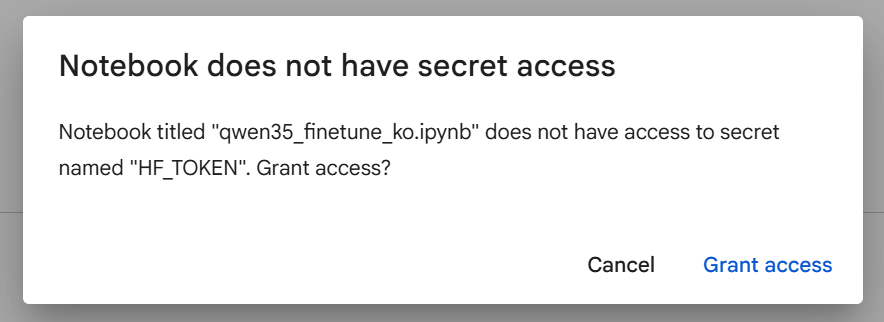


## 1. 모델 로드

In [2]:
from unsloth import FastVisionModel

# Qwen3.5-0.8B: Apache 2.0 공개 모델 — HF_TOKEN 불필요

model, tokenizer = FastVisionModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-0.8B",
    max_seq_length = 2048,
    load_in_4bit=False,
    use_gradient_checkpointing=True,
)

# LoRA 어댑터 부착
# 기반 모델 가중치는 항상 동결 — 어댑터만 학습됨
# finetune_* 플래그: 어댑터를 붙일 레이어 선택 (True = 해당 레이어에 어댑터 삽입)
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers     = True,   # 비전 인코더에 어댑터 삽입
    finetune_language_layers   = True,   # 언어 모델 레이어에 어댑터 삽입
    finetune_attention_modules = True,   # Attention (Q/K/V/O)에 어댑터 삽입
    finetune_mlp_modules       = True,   # MLP (gate/up/down)에 어댑터 삽입
    r            = 16,    # LoRA rank — 높을수록 학습 용량↑, VRAM↑
    lora_alpha   = 16,    # 스케일링 인수, 교육용으로 r과 동일하게 설정
    lora_dropout = 0,
    bias         = 'none',
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.7: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.
Unsloth: QLoRA and full finetuning 

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

## 2. 데이터셋

In [8]:
import io
from PIL import Image
from datasets import load_dataset

dataset = load_dataset("Sightation/SightationCompletions", split="train[:200]")

def to_pil(img):
    if isinstance(img, Image.Image):
        return img.convert("RGB")
    if isinstance(img, dict):
        if img.get("bytes") is not None:
            return Image.open(io.BytesIO(img["bytes"])).convert("RGB")
        if img.get("path"):
            return Image.open(img["path"]).convert("RGB")
    raise ValueError(f"Can't convert {type(img).__name__} to an image")

def convert_sample(sample):
    return {
        "messages": [
            {"role": "user", "content": [
                {"type": "image", "image": to_pil(sample["image"])},
                {"type": "text",  "text": sample["instruction"]},
            ]},
            {"role": "assistant", "content": [
                {"type": "text", "text": sample["response"]},
            ]},
        ]
    }

# Plain list, not dataset.map(), so the PIL images never pass through Arrow
dataset = [convert_sample(s) for s in dataset]

## 3. 콜레이터

In [9]:
from unsloth.trainer import UnslothVisionDataCollator

# 이미지 토크나이즈를 자동 처리해주는 VLM 전용 콜레이터
# 텍스트 전용 파인튜닝에는 불필요
collator = UnslothVisionDataCollator(model, tokenizer)

Unsloth: Model does not have a default image size - using 512


## 4. 학습

In [10]:
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model)   # 모델을 학습 모드로 전환 (필수)

trainer = SFTTrainer(
    model         = model,
    tokenizer     = tokenizer,
    data_collator = collator,
    train_dataset = dataset,
    args = SFTConfig(
        per_device_train_batch_size  = 2,
        gradient_accumulation_steps  = 4,   # 실효 배치 크기 = 8
        num_train_epochs             = 1,
        learning_rate                = 2e-4,
        fp16                         = False,
        bf16                         = False,
        max_grad_norm                = 1.0,
        logging_steps                = 10,
        output_dir                   = "outputs",
        remove_unused_columns        = False,  # VLM 데이터셋 필수 설정
        dataset_text_field           = "",     # 콜레이터가 형식 처리
        dataset_kwargs               = {"skip_prepare_dataset": True},
    ),
)



Unsloth: Switching to float32 training since model cannot work with float16


In [11]:
trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 200 | Num Epochs = 1 | Total steps = 25
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 13,181,952 of 866,167,872 (1.52% trained)


Step,Training Loss
10,1.707854
20,0.804404


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-25/tokenizer_config.json.


TrainOutput(global_step=25, training_loss=1.1507458972930908, metrics={'train_runtime': 373.7212, 'train_samples_per_second': 0.535, 'train_steps_per_second': 0.067, 'total_flos': 396953001131520.0, 'train_loss': 1.1507458972930908, 'epoch': 1.0})

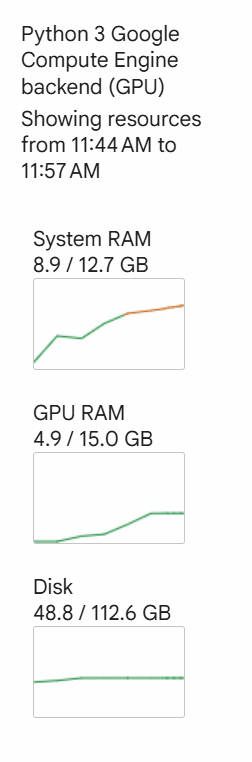

## 5. 추론

In [12]:
from PIL import Image
from datasets import load_dataset

FastVisionModel.for_inference(model)

sample = load_dataset("Sightation/SightationCompletions", split="train[0:1]")[0]
image = to_pil(sample["image"])
instruction = sample["instruction"]

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": image},
        {"type": "text",  "text": instruction},
    ],
}]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)
inputs = tokenizer(images=[image], text=[text], return_tensors="pt").to("cuda")

outputs = model.generate(**inputs, max_new_tokens=256)
print("=== 모델 출력 ===")
print(tokenizer.decode(outputs[0], skip_special_tokens=True))
print("\n=== 정답 (ground truth) ===")
print(sample["response"])

`causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


=== 모델 출력 ===
user
You are a helpful expert who is knowledgeable in various fields of academia. You are skilled in reading, interpreting, and understanding academic papers and figures contained therein. You are tasked with elaborating on the given information, which consists of a figure image. Write an informative and explanatory text in one paragraph under 200 words that describes the basic characteristics of the figure and incorporates important information. You may attempt to internally identify implicit points of curiosity for someone who is trying to understand the given figure, and then include explanations for those points in your response. Avoid mere reiteration of the given information as much as possible. You need not specify the origins of various parts of your response.
assistant
<think>

</think>

The image depicts a detailed diagram of a leaf, showcasing its various components. At the top, the leaflet is labeled, indicating the individual leaf segments that make up the le

## 6. 저장

In [13]:
# 옵션 A — LoRA 어댑터만 저장 (약 수십 MB, 빠름)
model.save_pretrained("qwen35_lora")
tokenizer.save_pretrained("qwen35_lora")

# 옵션 B — 베이스 모델과 병합 후 HuggingFace Hub에 업로드
# HF_TOKEN이 필요한 유일한 단계
# model.push_to_hub_merged(
#     "HF_사용자명/qwen35-ft",
#     tokenizer,
#     save_method="merged_16bit",
#     token="hf_...",
# )

Unsloth: Restored added_tokens_decoder metadata in qwen35_lora/tokenizer_config.json.


['qwen35_lora/processor_config.json']